# 17장 기대 자유 에너지와 계획 (실습)

16장의 이산 모델에 행동을 넣는다. Hydar 는 출발점에서 두 걸음을 움직일 수 있다. 먹이는 왼쪽 굴이나 오른쪽 굴 가운데 한 곳에 있고, 단서 바위에 가면 어느 쪽인지 알 수 있다. T-미로라 불리는 고전 과제다.

1. 생성 모델 — 위치 × 맥락, 세 가지 관측
2. 기대 자유 에너지 — 위험 + 모호성 = −(정보 이득) − (실용적 가치)
3. 정책 평가와 한 시행
4. 절제 실험 — 정보 이득을 빼거나 실용적 가치를 빼면
5. 정책 정밀도 γ
6. 사전이 기울 때 — 표준 계획과 정교한 추론
7. 선호가 지나치게 강할 때

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정

SEED = 1234
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

EPS = 1e-16
def ln(x):
    return np.log(x + EPS)

def softmax(v):
    e = np.exp(v - v.max())
    return e / e.sum()

print("softmax([0, 3, -6]) =", np.round(softmax(np.array([0.0, 3.0, -6.0])), 4))

softmax([0, 3, -6]) = [4.740e-02 9.525e-01 1.000e-04]


## 1. 생성 모델

숨은 상태는 위치(출발점, 단서 바위, 왼쪽 굴, 오른쪽 굴)와 맥락(먹이가 왼쪽, 먹이가 오른쪽)의 짝이다. 8 개의 결합 상태를 s = 위치 × 2 + 맥락 으로 번호 붙인다. 관측은 세 갈래다. 위치(그대로 보인다), 먹이(없음, 먹이, 독), 단서(없음, 왼쪽, 오른쪽). 행동 u 는 「어느 위치로 가는가」이고 B[u] 가 행동마다 다른 전이 행렬이다. 굴에 들어가면 나올 수 없다. 맥락은 시행 동안 바뀌지 않는다.

In [2]:
L, K = 4, 2                       # 위치 수, 맥락 수
S = L * K
loc_names = ["출발점", "단서 바위", "왼쪽 굴", "오른쪽 굴"]
def idx(l, c):
    return l * K + c

def build(p_food=0.98, p_cue=1.0):
    A_loc = np.zeros((L, S)); A_food = np.zeros((3, S)); A_cue = np.zeros((3, S))
    for l in range(L):
        for c in range(K):
            s = idx(l, c)
            A_loc[l, s] = 1
            if l in (2, 3):                                   # 굴: 맞는 굴이면 먹이, 틀린 굴이면 독
                good = (l - 2) == c
                A_food[1, s] = p_food if good else 1 - p_food
                A_food[2, s] = 1 - A_food[1, s]
            else:
                A_food[0, s] = 1
            if l == 1:                                        # 단서 바위: 맥락을 알려 준다
                A_cue[1 + c, s] = p_cue; A_cue[2 - c, s] = 1 - p_cue
            else:
                A_cue[0, s] = 1
    B = np.zeros((L, S, S))
    for u in range(L):
        for l in range(L):
            for c in range(K):
                nl = l if l in (2, 3) else u                  # 굴에서는 나올 수 없다
                B[u][idx(nl, c), idx(l, c)] = 1
    return [A_loc, A_food, A_cue], B

def Cvec(food=3.0, poison=-6.0):
    """관측에 대한 선호(로그 확률, softmax 전)"""
    return [np.zeros(L), np.array([0.0, food, poison]), np.zeros(3)]

As, B = build()
Cs = Cvec()
D = np.zeros(S); D[idx(0, 0)] = D[idx(0, 1)] = 0.5      # 출발점, 맥락은 반반
print("A_food (행: 없음/먹이/독, 열: 상태)\n", np.round(As[1], 2))
print("A_cue  (행: 없음/왼쪽/오른쪽)\n", np.round(As[2], 2))
print("선호 softmax(C_food) =", np.round(softmax(Cs[1]), 3))

A_food (행: 없음/먹이/독, 열: 상태)
 [[1.   1.   1.   1.   0.   0.   0.   0.  ]
 [0.   0.   0.   0.   0.98 0.02 0.02 0.98]
 [0.   0.   0.   0.   0.02 0.98 0.98 0.02]]
A_cue  (행: 없음/왼쪽/오른쪽)
 [[1. 1. 0. 0. 1. 1. 1. 1.]
 [0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0.]]
선호 softmax(C_food) = [0.047 0.952 0.   ]


## 2. 기대 자유 에너지

정책 π 를 따랐을 때 걸음 τ 의 예측 상태 s_τ = B[u_τ] s_τ−1, 예측 관측 o_τ = A s_τ 다. 한 걸음의 기대 자유 에너지는 위험(예측 관측과 선호의 KL)과 모호성(상태가 주어졌을 때 관측의 엔트로피 기댓값)의 합이다. 같은 양을 정보 이득과 실용적 가치로 다시 쓸 수 있다.

In [3]:
def H(A):
    """열마다 관측 분포의 엔트로피"""
    return -np.sum(A * ln(A), axis=0)

def step_G(s, As, Cs, w_epi=1.0, w_prag=1.0):
    """한 걸음의 G = −w_epi·(정보 이득) − w_prag·(실용적 가치)"""
    G = 0.0
    for A, C in zip(As, Cs):
        o = A @ s
        info = -o @ ln(o) - s @ H(A)          # H[o] − E_s[H[o|s]] = 상호 정보
        prag = o @ ln(softmax(C))             # 선호하는 관측의 기대 로그 확률
        G += -w_epi * info - w_prag * prag
    return G

def risk_ambiguity(s, As, Cs):
    risk = sum((A @ s) @ (ln(A @ s) - ln(softmax(C))) for A, C in zip(As, Cs))
    amb = sum(s @ H(A) for A in As)
    return risk, amb

s1 = B[1] @ D                                # 단서 바위로 간 뒤의 예측 상태
s2 = B[2] @ D                                # 왼쪽 굴로 간 뒤의 예측 상태
for name, s in [("단서 바위", s1), ("왼쪽 굴", s2)]:
    r, a = risk_ambiguity(s, As, Cs)
    print(f"{name}: 위험 {r:.3f} + 모호성 {a:.3f} = {r + a:.3f}   "
          f"−정보이득−실용 = {step_G(s, As, Cs):.3f}")

단서 바위: 위험 4.840 + 모호성 0.000 = 4.840   −정보이득−실용 = 4.840
왼쪽 굴: 위험 6.340 + 모호성 0.098 = 6.439   −정보이득−실용 = 6.439


## 3. 정책 평가와 한 시행

두 걸음짜리 정책 16 개의 G 를 모두 계산하고 q(π) = σ(−γG) 로 정책의 사후를 얻는다. 첫 행동은 정책 사후를 첫 행동별로 더한 분포에서 뽑는다. 한 걸음을 움직이고 관측으로 믿음을 고친 다음, 남은 한 걸음에 대해 다시 계획한다.

G 가 작은 정책 다섯
  단서 바위  → 단서 바위   G = 9.68  q(π) = 1.000
  출발점    → 단서 바위   G = 10.37  q(π) = 0.000
  단서 바위  → 출발점     G = 10.37  q(π) = 0.000
  출발점    → 출발점     G = 11.07  q(π) = 0.000
  단서 바위  → 왼쪽 굴    G = 11.28  q(π) = 0.000
첫 행동의 확률: {'출발점': np.float64(0.0), '단서 바위': np.float64(1.0), '왼쪽 굴': np.float64(0.0), '오른쪽 굴': np.float64(0.0)}


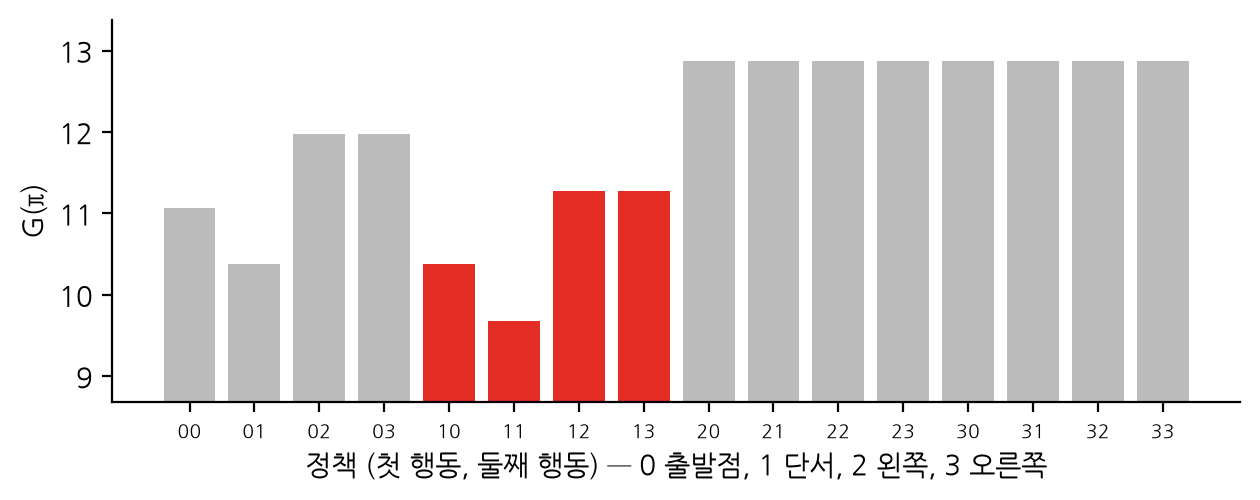

In [4]:
def G_policy(s, pi, As, B, Cs, **kw):
    G = 0.0
    for u in pi:
        s = B[u] @ s
        G += step_G(s, As, Cs, **kw)
    return G

def update(prior, obs, As):
    q = prior.copy()
    for A, o in zip(As, obs):
        q = q * A[o]
    return q / q.sum()

pols = list(itertools.product(range(L), repeat=2))
G0 = np.array([G_policy(D, pi, As, B, Cs) for pi in pols])
qpi = softmax(-16 * G0)
order = np.argsort(G0)
print("G 가 작은 정책 다섯")
for k in order[:5]:
    print(f"  {loc_names[pols[k][0]]:6s} → {loc_names[pols[k][1]]:6s}  G = {G0[k]:.2f}  q(π) = {qpi[k]:.3f}")
qu = np.zeros(L)
for p, pi in zip(qpi, pols):
    qu[pi[0]] += p
print("첫 행동의 확률:", dict(zip(loc_names, np.round(qu, 3))))

fig, ax = plt.subplots(figsize=(6.4, 2.6))
ax.bar(range(16), G0, color=["#E32C24" if pols[k][0] == 1 else "#BBBBBB" for k in range(16)])
ax.set_xticks(range(16)); ax.set_xticklabels([f"{a}{b}" for a, b in pols], fontsize=7)
ax.set_ylim(G0.min() - 1, G0.max() + 0.5)
ax.set_xlabel("정책 (첫 행동, 둘째 행동) — 0 출발점, 1 단서, 2 왼쪽, 3 오른쪽"); ax.set_ylabel("G(π)")
plt.tight_layout(); plt.show()

In [5]:
def trial(rng, As, B, Cs, ctx, D, gamma=16.0, T=2, verbose=False, **kw):
    s_true = idx(0, ctx); q = D.copy(); path = []; foods = []
    for t in range(T):
        pols_t = list(itertools.product(range(L), repeat=T - t))
        G = np.array([G_policy(q, pi, As, B, Cs, **kw) for pi in pols_t])
        qp = softmax(-gamma * G)
        qu = np.zeros(L)
        for p, pi in zip(qp, pols_t):
            qu[pi[0]] += p
        u = rng.choice(L, p=qu / qu.sum())
        s_true = np.argmax(B[u][:, s_true])
        obs = [rng.choice(A.shape[0], p=A[:, s_true]) for A in As]
        q = update(B[u] @ q, obs, As)
        path.append(u); foods.append(obs[1])
        if verbose:
            belief_ctx = q.reshape(L, K).sum(0)
            print(f"걸음 {t + 1}: {loc_names[u]:6s} 관측(먹이 {['없음', '먹이', '독'][obs[1]]}, "
                  f"단서 {['없음', '왼쪽', '오른쪽'][obs[2]]})  믿음 p(먹이가 오른쪽) = {belief_ctx[1]:.3f}")
    return path, foods

print("먹이가 오른쪽에 있는 시행")
_ = trial(np.random.default_rng(SEED), As, B, Cs, ctx=1, D=D, verbose=True)

먹이가 오른쪽에 있는 시행
걸음 1: 단서 바위  관측(먹이 없음, 단서 오른쪽)  믿음 p(먹이가 오른쪽) = 1.000
걸음 2: 오른쪽 굴  관측(먹이 먹이, 단서 없음)  믿음 p(먹이가 오른쪽) = 1.000


## 4. 절제 실험

G 의 두 항 가운데 하나를 빼고 200 번의 시행을 돌린다. 맥락은 시행마다 반반으로 정한다. 첫 걸음에 단서 바위로 간 비율, 마지막 걸음에 먹이를 얻은 비율, 독을 얻은 비율을 센다.

In [6]:
def batch(n=200, seed=0, p_ctx=0.5, Cs=None, planner=None, **kw):
    rng = np.random.default_rng(seed)
    Dp = np.zeros(S); Dp[idx(0, 0)] = p_ctx; Dp[idx(0, 1)] = 1 - p_ctx
    Cs = Cvec() if Cs is None else Cs
    run = planner or trial
    cue = food = poison = 0
    for k in range(n):
        ctx = 0 if rng.random() < p_ctx else 1
        path, foods = run(rng, As, B, Cs, ctx, Dp, **kw)
        cue += path[0] == 1; food += foods[-1] == 1; poison += foods[-1] == 2
    return cue / n, food / n, poison / n

print(f"{'에이전트':14s}{'단서 먼저':>8s}{'먹이':>8s}{'독':>8s}")
for name, kw in [("완전한 G", {}), ("실용적 가치만", {"w_epi": 0}), ("정보 이득만", {"w_prag": 0})]:
    c, f, p = batch(**kw)
    print(f"{name:14s}{c:8.3f}{f:8.3f}{p:8.3f}")

에이전트             단서 먼저      먹이       독
완전한 G            1.000   0.965   0.035
실용적 가치만          0.485   0.460   0.025


정보 이득만           0.800   0.310   0.275


## 5. 정책 정밀도 γ

γ 는 G 의 차이를 얼마나 믿고 행동할지를 정한다. 작으면 정책 사후가 평평해져 거의 무작위로 고른다.

γ =  0.25:  단서 먼저 0.380  먹이 0.390  독 0.255
γ =   0.5:  단서 먼저 0.440  먹이 0.410  독 0.215
γ =     1:  단서 먼저 0.645  먹이 0.595  독 0.125
γ =     2:  단서 먼저 0.840  먹이 0.810  독 0.035
γ =     4:  단서 먼저 0.960  먹이 0.925  독 0.035
γ =     8:  단서 먼저 1.000  먹이 0.965  독 0.035
γ =    16:  단서 먼저 1.000  먹이 0.965  독 0.035


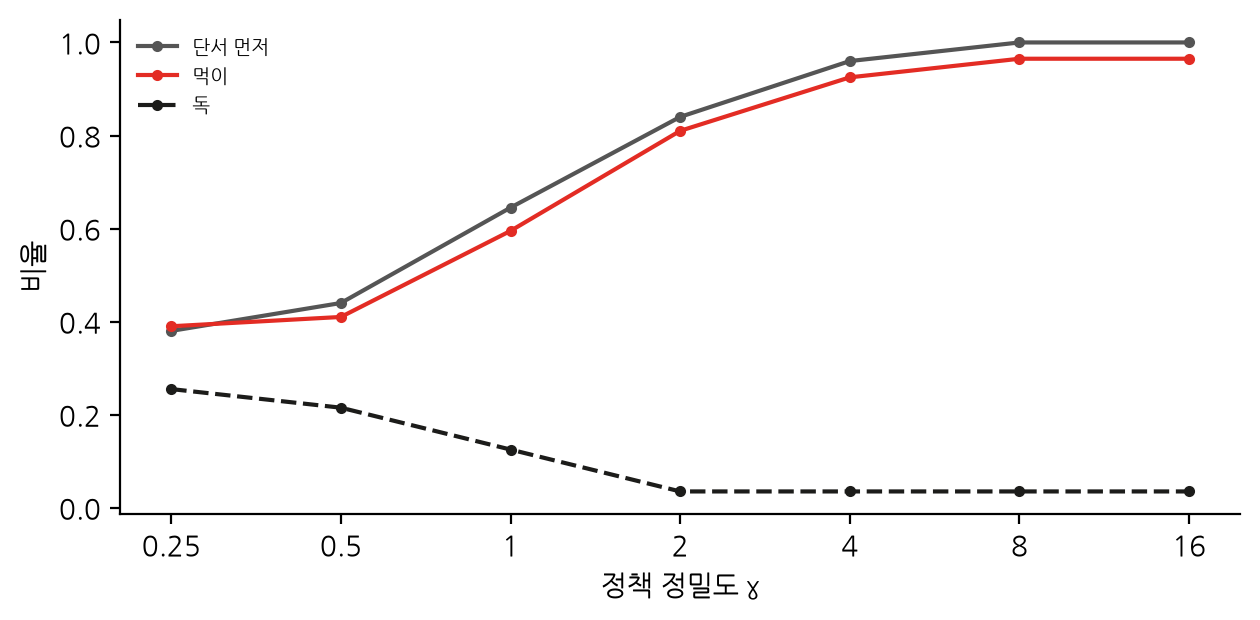

In [7]:
gammas = [0.25, 0.5, 1, 2, 4, 8, 16]
res = np.array([batch(gamma=g) for g in gammas])
for g, (c, f, p) in zip(gammas, res):
    print(f"γ = {g:5}:  단서 먼저 {c:.3f}  먹이 {f:.3f}  독 {p:.3f}")
fig, ax = plt.subplots()
ax.plot(gammas, res[:, 0], "o-", color="#555555", ms=3, label="단서 먼저")
ax.plot(gammas, res[:, 1], "o-", color="#E32C24", ms=3, label="먹이")
ax.plot(gammas, res[:, 2], "o--", color="#1C1C1A", ms=3, label="독")
ax.set_xscale("log"); ax.set_xticks(gammas); ax.set_xticklabels([str(g) for g in gammas]); ax.minorticks_off(); ax.set_xlabel("정책 정밀도 γ"); ax.set_ylabel("비율")
ax.legend(fontsize=7, frameon=False); plt.tight_layout(); plt.show()

## 6. 사전이 기울 때 — 표준 계획과 정교한 추론

표준 계획은 정책을 통째로 평가한다. 「단서 바위 → 왼쪽 굴」의 둘째 걸음을 평가할 때 단서를 본 뒤의 믿음이 아니라 지금의 믿음을 쓴다. 정교한 추론(sophisticated inference)은 걸음마다 나올 수 있는 관측을 펼쳐 믿음을 고친 뒤 다음 행동을 고른다고 가정하고 G 를 재귀로 계산한다. 먹이가 왼쪽에 있을 사전 확률 p 를 바꾸며 둘을 비교한다.

    p |    표준: 단서     먹이 |    정교: 단서     먹이
 0.50 |     1.000  0.965 |     1.000  0.965
 0.60 |     1.000  0.965 |     1.000  0.965
 0.70 |     0.035  0.670 |     1.000  0.965
 0.80 |     0.000  0.730 |     1.000  0.965
 0.90 |     0.000  0.850 |     0.000  0.850
 0.95 |     0.000  0.915 |     0.000  0.915
정교한 추론, 실용적 가치만: (1.0, 0.965, 0.035)


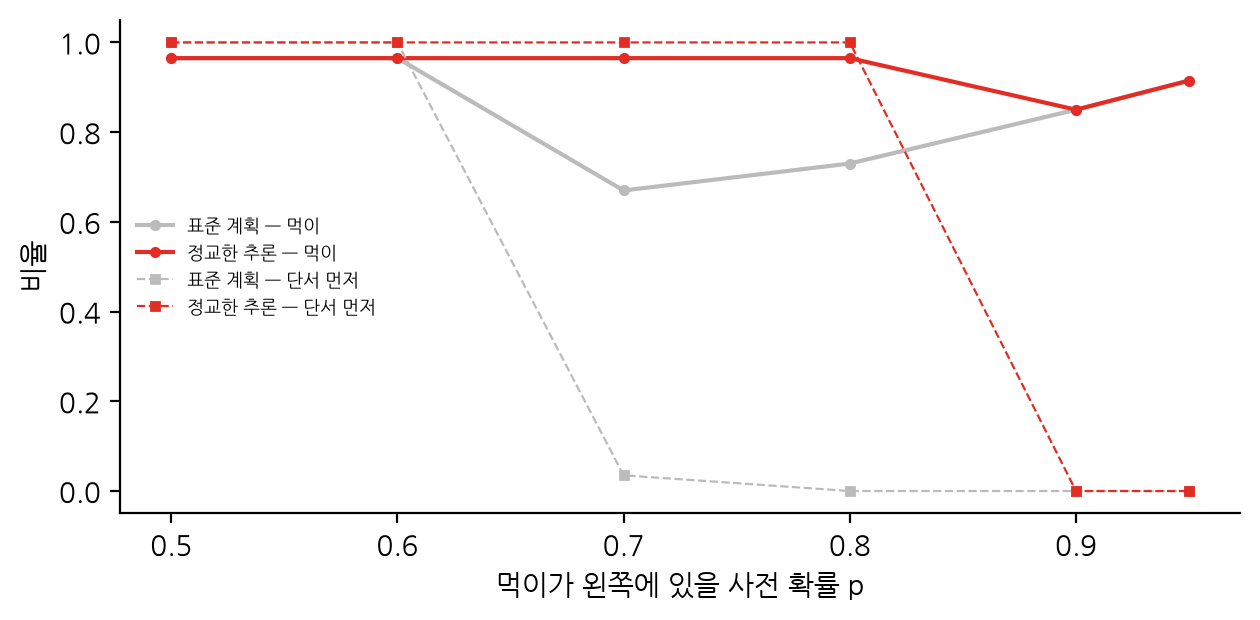

In [8]:
def G_soph(q, depth, As, B, Cs, gamma=16.0, **kw):
    Gs = np.zeros(L)
    for u in range(L):
        s = B[u] @ q
        g = step_G(s, As, Cs, **kw)
        if depth > 1:
            for obs in itertools.product(*[range(A.shape[0]) for A in As]):
                po = s.copy()
                for A, o in zip(As, obs):
                    po = po * A[o]
                p = po.sum()
                if p < 1e-6:
                    continue
                Gn = G_soph(po / p, depth - 1, As, B, Cs, gamma, **kw)
                g += p * (softmax(-gamma * Gn) @ Gn)       # 다음 걸음에 고를 행동의 G 기댓값
        Gs[u] = g
    return Gs

def trial_soph(rng, As, B, Cs, ctx, D, gamma=16.0, T=2, **kw):
    s_true = idx(0, ctx); q = D.copy(); path = []; foods = []
    for t in range(T):
        qu = softmax(-gamma * G_soph(q, T - t, As, B, Cs, gamma, **kw))
        u = rng.choice(L, p=qu)
        s_true = np.argmax(B[u][:, s_true])
        obs = [rng.choice(A.shape[0], p=A[:, s_true]) for A in As]
        q = update(B[u] @ q, obs, As)
        path.append(u); foods.append(obs[1])
    return path, foods

ps = [0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
std = np.array([batch(p_ctx=p) for p in ps])
soph = np.array([batch(p_ctx=p, planner=trial_soph) for p in ps])
print(f"{'p':>5s} | {'표준: 단서':>9s}{'먹이':>7s} | {'정교: 단서':>9s}{'먹이':>7s}")
for p, a, b in zip(ps, std, soph):
    print(f"{p:5.2f} | {a[0]:9.3f}{a[1]:7.3f} | {b[0]:9.3f}{b[1]:7.3f}")
print("정교한 추론, 실용적 가치만:", batch(planner=trial_soph, w_epi=0))

fig, ax = plt.subplots()
ax.plot(ps, std[:, 1], "o-", color="#BBBBBB", ms=3, label="표준 계획 — 먹이")
ax.plot(ps, soph[:, 1], "o-", color="#E32C24", ms=3, label="정교한 추론 — 먹이")
ax.plot(ps, std[:, 0], "s--", color="#BBBBBB", ms=3, lw=0.8, label="표준 계획 — 단서 먼저")
ax.plot(ps, soph[:, 0], "s--", color="#E32C24", ms=3, lw=0.8, label="정교한 추론 — 단서 먼저")
ax.set_xlabel("먹이가 왼쪽에 있을 사전 확률 p"); ax.set_ylabel("비율")
ax.legend(fontsize=6.5, frameon=False, loc="center left"); plt.tight_layout(); plt.show()

## 7. 선호가 지나치게 강할 때

먹이의 선호 C 를 키우면 「굴에 일찍 들어가 두 걸음 내내 먹이를 볼」 기대가 커진다. 반반의 도박이라도 그 기대가 단서의 정보 가치를 넘어서면 표준 계획은 단서를 건너뛴다.

In [9]:
print(f"{'C(먹이)':>8s} | {'표준: 단서':>9s}{'먹이':>7s}{'독':>7s} | {'정교: 단서':>9s}{'먹이':>7s}")
for r in [1, 3, 6, 9, 12]:
    a = batch(Cs=Cvec(r, -6)); b = batch(Cs=Cvec(r, -6), planner=trial_soph)
    print(f"{r:8d} | {a[0]:9.3f}{a[1]:7.3f}{a[2]:7.3f} | {b[0]:9.3f}{b[1]:7.3f}")

   C(먹이) |    표준: 단서     먹이      독 |    정교: 단서     먹이
       1 |     1.000  0.965  0.035 |     1.000  0.965


       3 |     1.000  0.965  0.035 |     1.000  0.965
       6 |     0.800  0.845  0.155 |     1.000  0.965


       9 |     0.000  0.470  0.530 |     1.000  0.965


      12 |     0.000  0.470  0.530 |     1.000  0.965
